## 1. 원본 로딩과 분석 구조

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATASET_KEY = "서울특별시 강남구_흡연단속내역_20260227"

def find_project():
    cwd = Path.cwd().resolve()
    for base in [cwd, *cwd.parents]:
        if base.name == "do_not_lung" and (base / "notebooks").is_dir():
            return base
        candidate = base / "do_not_lung"
        if (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError("do_not_lung 저장소를 Path.cwd()의 상위 경로에서 찾지 못했습니다.")

REPO = find_project()
DATA_ROOT = REPO.parent / "data"
RAW_ROOT = DATA_ROOT / "raw_data"
OUT_DIR = DATA_ROOT / "processed_data" / DATASET_KEY
candidates = sorted(RAW_ROOT.rglob(f"{DATASET_KEY}*.csv"),
                    key=lambda p: (p.name != f"{DATASET_KEY}.csv", str(p)))
if not candidates:
    raise FileNotFoundError(f"원본 파일 없음: {RAW_ROOT} 내부에서 {DATASET_KEY}*.csv를 찾지 못했습니다.")
RAW_PATH = candidates[0]

raw = None
for encoding in ["utf-8-sig", "cp949", "euc-kr"]:
    try:
        raw = pd.read_csv(RAW_PATH, encoding=encoding, dtype="string", keep_default_na=True)
        break
    except UnicodeDecodeError:
        continue
if raw is None:
    raise UnicodeError("원본 CSV의 인코딩을 판별하지 못했습니다.")

expected = ["연번", "위반내용", "부과금액", "위반장소", "위반일시"]
missing_columns = sorted(set(expected) - set(raw.columns))
if missing_columns:
    raise ValueError(f"원본의 필수 컬럼이 없습니다: {missing_columns}")
if raw.columns.duplicated().any():
    raise ValueError("원본 컬럼명이 중복됩니다. 명세를 먼저 확인하세요.")
selected = raw.copy() # 자치구 컬럼 없음: 파일명에 명시된 강남구 자료 전체를 분석
selected.insert(0, "source_row_id", np.arange(1, len(selected)+1, dtype=np.int64))
print("원본 파일:", RAW_PATH.name, " / 인코딩:", encoding)
print("원본:", raw.shape, " / 강남구 파일 전체:", selected.shape)
print("원본 메모리(MiB):", round(raw.memory_usage(deep=True).sum()/1024**2,3))
print("원본 자료형:")
display(raw.dtypes.to_frame("dtype"))
print("원본 첫 5행:")
display(raw.head())
print("원본 컬럼별 고유값 개수:")
display(raw.nunique(dropna=True).to_frame("unique_values"))
print("주의: 강남구 여부는 파일 출처명에 근거하며, 원본에 행 단위 시군구/좌표 컬럼은 없습니다.")


원본 파일: 서울특별시 강남구_흡연단속내역_20260227 (1).csv  / 인코딩: cp949
원본: (5629, 5)  / 강남구 파일 전체: (5629, 6)
원본 메모리(MiB): 1.818
원본 자료형:


,dtype
연번,string[python]
위반내용,string[python]
부과금액,string[python]
위반장소,string[python]
위반일시,string[python]


원본 첫 5행:


,연번,위반내용,부과금액,위반장소,위반일시
0,1,금연구역에서 흡연,100000,도곡중학교금연거리,2022-01-03 11:07
1,2,금연구역에서 흡연,100000,도곡중학교금연거리,2022-01-03 11:09
2,3,금연구역에서 흡연,100000,도곡중학교금연거리,2022-01-03 11:10
3,4,금연구역에서 흡연,100000,건물,2022-01-04 11:20
4,5,금연구역에서 흡연,100000,건물,2022-01-04 11:21


원본 컬럼별 고유값 개수:


,unique_values
연번,5629
위반내용,12
부과금액,3
위반장소,423
위반일시,5431


주의: 강남구 여부는 파일 출처명에 근거하며, 원본에 행 단위 시군구/좌표 컬럼은 없습니다.


## 2. 품질 진단과 보존형 전처리

In [2]:
clean = selected.copy()
original_cols = list(raw.columns)
for col in original_cols:
    clean[col] = clean[col].astype("string") # 원본 컬럼의 공백·표기 그대로 보존

# 원본을 덮어쓰지 않고 별도 표준화 열 생성
clean["violation_text_normalized"] = (
    clean["위반내용"].str.strip().str.replace(r"\s+", " ", regex=True)
)
clean["location_text_normalized"] = (
    clean["위반장소"].str.strip().str.replace(r"\s+", " ", regex=True)
)
clean["amount_krw"] = pd.to_numeric(
    clean["부과금액"].str.replace(",", "", regex=False).str.strip(),
    errors="coerce"
).astype("Int64")
clean["violation_datetime"] = pd.to_datetime(
    clean["위반일시"].str.strip(),
    format="%Y-%m-%d %H:%M", errors="coerce"
)
clean["violation_date"] = clean["violation_datetime"].dt.strftime("%Y-%m-%d")
clean["year"] = clean["violation_datetime"].dt.year.astype("Int64")
clean["month"] = clean["violation_datetime"].dt.month.astype("Int64")
clean["day"] = clean["violation_datetime"].dt.day.astype("Int64")
clean["hour"] = clean["violation_datetime"].dt.hour.astype("Int64")
clean["weekday"] = clean["violation_datetime"].dt.dayofweek.astype("Int64")
clean["is_weekend"] = clean["weekday"].ge(5).astype("boolean")
clean["year_month"] = clean["violation_datetime"].dt.strftime("%Y-%m")
clean["case_id_valid"] = clean["연번"].str.fullmatch(r"[0-9]+", na=False).astype(bool)
clean["duplicate_case_id_flag"] = clean["연번"].duplicated(keep=False) & clean["연번"].notna()
clean["duplicate_original_row_flag"] = raw.duplicated(keep=False)
key_cols = ["violation_text_normalized", "location_text_normalized", "amount_krw", "violation_datetime"]
clean["possible_repeated_event_flag"] = clean.duplicated(subset=key_cols, keep=False)
clean["datetime_parse_failed_flag"] = clean["violation_datetime"].isna()
clean["amount_invalid_flag"] = clean["amount_krw"].isna() | clean["amount_krw"].lt(0).fillna(False)
clean["location_missing_flag"] = clean["location_text_normalized"].isna() | clean["location_text_normalized"].eq("").fillna(False)
clean["record_after_filename_date_flag"] = clean["violation_datetime"].dt.date.gt(
    pd.Timestamp("2026-02-27").date()
).fillna(False)
amount_frequency = clean["amount_krw"].value_counts(dropna=False)
clean["rare_amount_flag"] = clean["amount_krw"].map(amount_frequency).le(1).fillna(False)

# 단순 표기(유형)인지 여부를 나타내는 후보. 지오코딩 실패 여부와는 다름.
generic_labels = {
    "건물", "학교", "어린이집", "PC방", "지하철역", "지하철역출입구", "버스정류장",
    "카페", "청사", "공영주차장", "음식점", "휴게음식점", "병원", "교육기관", "금연거리"
}
clean["generic_location_label_flag"] = clean["location_text_normalized"].isin(generic_labels)

# 원본 문구의 키워드로만 만든 임시 공간 유형 후보 (공식 행정분류/실제 좌표 아님)
keywords = [
    ("어린이집", "어린이집 표현"),
    ("PC방", "PC방 표현"),
    ("지하철", "지하철 관련 표현"),
    ("버스정류", "버스정류소 관련 표현"),
    ("금연거리", "금연거리 표현"),
    ("주차장", "주차장 표현"),
    ("학교", "학교 표현"),
    ("카페", "카페 표현"),
    ("음식점", "음식점 표현"),
    ("병원", "병원 표현"),
    ("건물", "건물 표현"),
    ("청사", "청사 표현"),
]

def location_keyword_hint(value):
    if pd.isna(value) or not str(value).strip():
        return "장소 미상"
    for word, label in keywords:
        if word in str(value):
            return label
    return "기타/분류되지 않음"

clean["location_keyword_hint"] = clean["location_text_normalized"].map(location_keyword_hint).astype("string")
clean["review_needed"] = (
    ~clean["case_id_valid"]
    | clean["duplicate_case_id_flag"]
    | clean["duplicate_original_row_flag"]
    | clean["possible_repeated_event_flag"]
    | clean["datetime_parse_failed_flag"]
    | clean["amount_invalid_flag"]
    | clean["location_missing_flag"]
    | clean["record_after_filename_date_flag"]
)
# 유효할 수도 있는 반복 적발/희귀 과태료 기록은 삭제하거나 숫자를 변경하지 않는다.
missing = pd.DataFrame({
    "missing_count": raw.isna().sum(),
    "missing_pct": (raw.isna().mean()*100).round(4),
    "unique_count": raw.nunique(dropna=True)
})
print("결측/고유값:")
display(missing)
print("전처리 전:", selected.shape, "/ 전처리 후:", clean.shape)
print("검토 플래그별 행 수:")
flags = [c for c in clean.columns if c.endswith("_flag") or c in ["review_needed", "case_id_valid"]]
display(pd.DataFrame({"flag":flags, "true_rows":[int(clean[c].fillna(False).sum()) for c in flags]}))
print("기준일/관측일:",clean["violation_datetime"].min(), clean["violation_datetime"].max())
print("주의: 같은 장소·분에 연속 단속된 사건은 서로 다른 적발일 수 있습니다.")


결측/고유값:


,missing_count,missing_pct,unique_count
연번,0,0.0,5629
위반내용,0,0.0,12
부과금액,0,0.0,3
위반장소,0,0.0,423
위반일시,0,0.0,5431


전처리 전: (5629, 6) / 전처리 후: (5629, 30)
검토 플래그별 행 수:


,flag,true_rows
0,case_id_valid,5629
1,duplicate_case_id_flag,0
2,duplicate_original_row_flag,0
3,possible_repeated_event_flag,201
4,datetime_parse_failed_flag,0
5,amount_invalid_flag,0
6,location_missing_flag,0
7,record_after_filename_date_flag,0
8,rare_amount_flag,1
9,generic_location_label_flag,2706


기준일/관측일: 2022-01-03 11:07:00 2026-02-27 13:50:00
주의: 같은 장소·분에 연속 단속된 사건은 서로 다른 적발일 수 있습니다.


## 3. 기초 통계와 시공간 활용성

In [3]:
print("연도별 적발 건수:")
display(clean["year"].value_counts(dropna=False).sort_index().rename("records").to_frame())
print("위반내용 (공백 정규화):")
display(clean["violation_text_normalized"].value_counts(dropna=False).to_frame("records"))
print("과태료 분포 (원):")
display(clean["amount_krw"].value_counts(dropna=False).sort_index().to_frame("records"))
print("장소 문구 상위 25개:")
display(clean["location_text_normalized"].value_counts(dropna=False).head(25).to_frame("records"))
print("키워드 기반 공간 유형 후보:")
display(clean["location_keyword_hint"].value_counts(dropna=False).to_frame("records"))
print("수치형 통계:")
display(clean[["amount_krw", "year", "month", "hour", "weekday"]].describe())
print("일자별 중복 기재 가능성:")
display(clean.loc[clean["possible_repeated_event_flag"], ["연번", "위반내용", "부과금액", "위반장소", "위반일시"]].head(20))
print("공간/시간 확인:")
print("- 시간: 위반일시에서 연도·월·요일·시간대 분석 가능")
print("- 공간: 위반장소는 자유 텍스트. 위도·경도·행정동코드·250m격자 열 없음")
print("- 강남구 자체 데이터이므로 자치구 필터 없음; 행별 강남구 소재지 확인 불가")


연도별 적발 건수:


,records
year,
2022,1434
2023,743
2024,1228
2025,1897
2026,327


위반내용 (공백 정규화):


,records
violation_text_normalized,
금연구역에서 흡연,5559
시설전체 금연구역에서 흡연,50
공동주택의 금연구역에서 흡연,12
금연구역내에서 흡연,2
국민건강증진법 제9조제8항 위반(금연구역내 흡연행위),2
시설부분 금연구역에서 흡연,1
금연건물 내 흡연(수서경찰서 공문통보),1
시설전체 금연구역에서 흡연(코엑스1층하역장),1
금연구역에서 흡연(미진프라자앞),1


과태료 분포 (원):


,records
amount_krw,
25000,1
50000,698
100000,4930


... (5 outputs left out)

,amount_krw,year,month,hour,weekday
count,5629.0,5629.0,5629.0,5629.0,5629.0
mean,93786.640611,2023.811689,6.759815,12.726772,2.020608
std,16505.866564,1.298158,3.767762,2.330531,1.383449
min,25000.0,2022.0,1.0,1.0,0.0
25%,100000.0,2022.0,3.0,11.0,1.0
50%,100000.0,2024.0,7.0,12.0,2.0
75%,100000.0,2025.0,10.0,15.0,3.0
max,100000.0,2026.0,12.0,22.0,6.0


일자별 중복 기재 가능성:


,연번,위반내용,부과금액,위반장소,위반일시
19,20,금연구역에서 흡연,100000,휴게음식점,2022-01-11 15:31
20,21,금연구역에서 흡연,100000,휴게음식점,2022-01-11 15:31
237,238,금연구역에서 흡연,100000,건물,2022-04-04 13:34
267,268,금연구역에서 흡연,100000,건물,2022-04-04 13:34
268,269,금연구역에서 흡연,100000,건물,2022-04-04 13:34
1417,1418,금연구역에서 흡연,100000,병원,2022-12-29 14:22
1698,1699,금연구역에서 흡연,100000,병원,2022-12-29 14:22
1751,1752,금연구역에서 흡연,100000,PC방,2023-08-07 15:47
1752,1753,금연구역에서 흡연,100000,PC방,2023-08-07 15:47
1757,1758,금연구역에서 흡연,100000,건물,2023-08-08 15:07


공간/시간 확인:
- 시간: 위반일시에서 연도·월·요일·시간대 분석 가능
- 공간: 위반장소는 자유 텍스트. 위도·경도·행정동코드·250m격자 열 없음
- 강남구 자체 데이터이므로 자치구 필터 없음; 행별 강남구 소재지 확인 불가


## 4. 분포 시각화

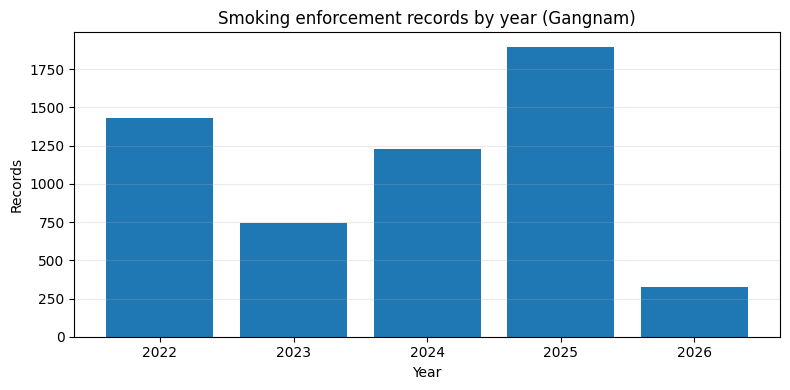

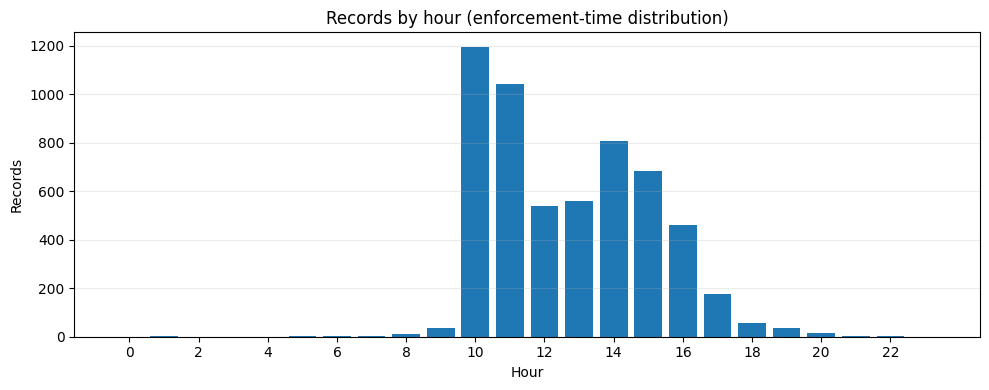

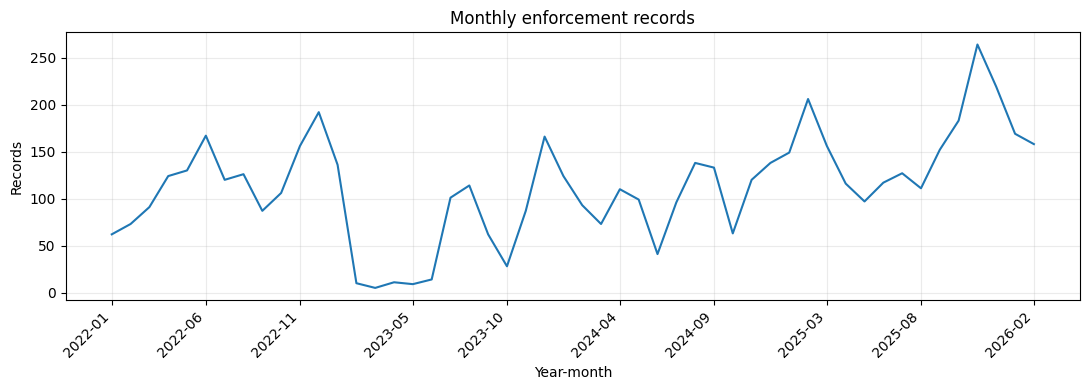

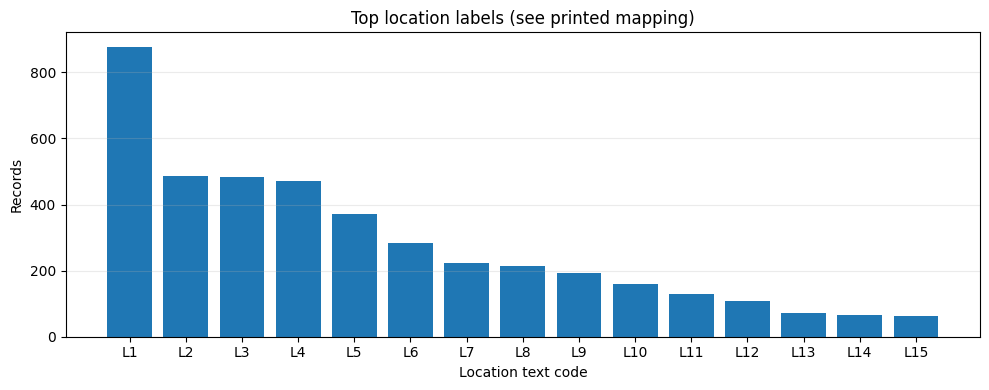

상위 장소 코드표:
L1: 건물 (877)
L2: 어린이집 (485)
L3: PC방 (483)
L4: 영동대로 금연거리 (472)
L5: 도곡중학교금연거리 (370)
L6: 학교 (285)
L7: 풀무원 어린이집(수서역) (223)
L8: 도곡중 금연거리 (214)
L9: 강남대로 금연거리 (193)
L10: 지하철역 (159)
L11: 영동대로 (128)
L12: 강남대로 (107)
L13: 카페 (73)
L14: 지하철역출입구 (67)
L15: 어린이집 시설경계30 (64)


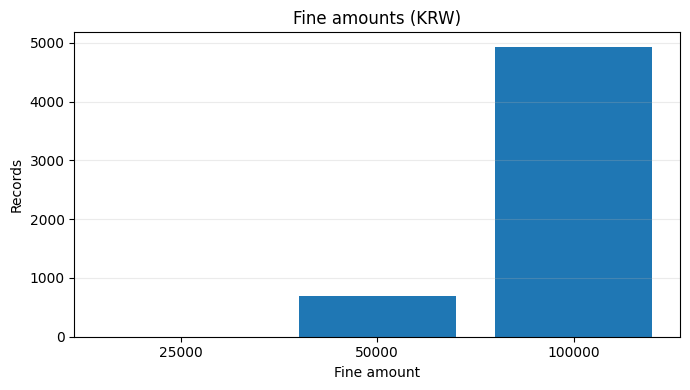

In [4]:
yearly = clean["year"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8,4))
ax.bar(yearly.index.astype(int).astype(str), yearly.values)
ax.set(title="Smoking enforcement records by year (Gangnam)", xlabel="Year", ylabel="Records")
ax.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()
plt.close(fig)

hourly = clean["hour"].value_counts().reindex(range(24), fill_value=0)
fig, ax = plt.subplots(figsize=(10,4))
ax.bar(hourly.index, hourly.values)
ax.set(title="Records by hour (enforcement-time distribution)", xlabel="Hour", ylabel="Records", xticks=range(0,24,2))
ax.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()
plt.close(fig)

monthly = clean["year_month"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(11,4))
ax.plot(np.arange(len(monthly)),monthly.values,linewidth=1.5)
if len(monthly):
    ticks = np.linspace(0,len(monthly)-1,min(10,len(monthly)),dtype=int)
    ax.set_xticks(ticks,monthly.index[ticks],rotation=45,ha="right")
ax.set(title="Monthly enforcement records", xlabel="Year-month", ylabel="Records")
ax.grid(alpha=.25)
plt.tight_layout()
plt.show()
plt.close(fig)

top_locations = clean["location_text_normalized"].value_counts().head(15)
fig, ax = plt.subplots(figsize=(10,4))
ax.bar([f"L{i+1}" for i in range(len(top_locations))],top_locations.values)
ax.set(title="Top location labels (see printed mapping)", xlabel="Location text code", ylabel="Records")
ax.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()
plt.close(fig)
print("상위 장소 코드표:")
for i,(name,count) in enumerate(top_locations.items(),1):
    print(f"L{i}: {name} ({count})")

fine = clean["amount_krw"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7,4))
ax.bar(fine.index.astype(int).astype(str),fine.values)
ax.set(title="Fine amounts (KRW)", xlabel="Fine amount", ylabel="Records")
ax.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()
plt.close(fig)


## 5. 모델 입력변수 후보와 통계 테이블

In [5]:
# 원본의 모든 행은 '적발 기록'이므로 미적발(0) 학습 라벨을 생성하지 않는다.
# 사건 발생 후 결정되는 부과금액은 학습 X에서 제외 (정보누수 방지).
features = clean[[
    "source_row_id", "연번", "violation_datetime", "violation_date",
    "location_text_normalized", "location_keyword_hint",
    "year", "month", "day", "hour", "weekday", "is_weekend",
    "generic_location_label_flag", "possible_repeated_event_flag", "review_needed"
]].copy()
features = features.rename(columns={
    "연번":"source_case_id",
    "violation_datetime":"event_datetime",
    "violation_date":"event_date",
    "location_text_normalized":"location_text",
})
features["hour_sin"] = np.sin(2*np.pi*features["hour"].astype("Float64")/24)
features["hour_cos"] = np.cos(2*np.pi*features["hour"].astype("Float64")/24)
features["weekday_sin"] = np.sin(2*np.pi*features["weekday"].astype("Float64")/7)
features["weekday_cos"] = np.cos(2*np.pi*features["weekday"].astype("Float64")/7)
# 실제 텍스트에서 도출된 유형 표현에 대한 one-hot만 생성
hints = pd.get_dummies(clean["location_keyword_hint"], prefix="place_hint", dtype="int8")
features = pd.concat([features,hints],axis=1)

records=[]
def add(section,metric,category,value,unit=""):
    records.append({"section":section,"metric":metric,"category":category,"value":value,"unit":unit})

add("structure","raw_rows","",len(raw),"records")
add("structure","raw_columns","",len(raw.columns),"columns")
add("structure","clean_rows","",len(clean),"records")
add("structure","clean_columns","",len(clean.columns),"columns")
add("structure","features_rows","",len(features),"records")
add("structure","features_columns","",len(features.columns),"columns")
add("structure","raw_memory_mib","",round(raw.memory_usage(deep=True).sum()/1024**2,6),"MiB")
add("structure","unique_location_labels_raw","",raw["위반장소"].nunique(),"labels")
add("structure","unique_location_labels_normalized","",clean["location_text_normalized"].nunique(),"labels")
add("structure","has_coordinates","",0,"boolean")
for c in original_cols:
    add("missing","count",c,int(raw[c].isna().sum()),"records")
    add("missing","percent",c,round(raw[c].isna().mean()*100,5),"percent")
    add("unique","count",c,int(raw[c].nunique(dropna=True)),"values")
for flag in flags:
    add("quality","true_rows",flag,int(clean[flag].fillna(False).sum()),"records")
add("quality","same_event_key_duplicates_excluding_first","",int(clean.duplicated(key_cols).sum()),"records")
for section,column in [
    ("year","year"),("month","month"),("hour","hour"),("weekday","weekday"),
    ("violation_text","violation_text_normalized"),
    ("location_label","location_text_normalized"),
    ("location_keyword_hint","location_keyword_hint"),
    ("amount","amount_krw")
]:
    for category,count in clean[column].value_counts(dropna=False).items():
        add(section,"record_count",str(category) if not pd.isna(category) else "(결측)",int(count),"records")
for col in ["amount_krw","hour","year"]:
    for stat in ["min","max","mean","median","std"]:
        v=getattr(clean[col],stat)()
        add("numeric",stat,col,v,"KRW" if col=="amount_krw" else "")
for category,count in clean["year_month"].value_counts(dropna=False).sort_index().items():
    add("year_month","record_count",str(category),int(count),"records")
summary=pd.DataFrame(records, columns=["section","metric","category","value","unit"])
print("clean:",clean.shape,"summary:",summary.shape,"features:",features.shape)
display(features.head())
print("주의: 이 데이터의 개별 행은 적발 사건 양성 관측이며, 흡연 미발생 샘플/음성 라벨은 없습니다.")


clean: (5629, 30) summary: (557, 5) features: (5629, 32)


,source_row_id,source_case_id,event_datetime,event_date,location_text,location_keyword_hint,year,month,day,hour,weekday,is_weekend,generic_location_label_flag,possible_repeated_event_flag,review_needed,hour_sin,hour_cos,weekday_sin,weekday_cos,place_hint_PC방 표현,place_hint_건물 표현,place_hint_금연거리 표현,place_hint_기타/분류되지 않음,place_hint_버스정류소 관련 표현,place_hint_병원 표현,place_hint_어린이집 표현,place_hint_음식점 표현,place_hint_주차장 표현,place_hint_지하철 관련 표현,place_hint_청사 표현,place_hint_카페 표현,place_hint_학교 표현
0,1,1,2022-01-03 11:07:00,2022-01-03,도곡중학교금연거리,금연거리 표현,2022,1,3,11,0,False,False,False,False,0.258819,-0.965926,0.0,1.0,0,0,1,0,0,0,0,0,0,0,0,0,0
1,2,2,2022-01-03 11:09:00,2022-01-03,도곡중학교금연거리,금연거리 표현,2022,1,3,11,0,False,False,False,False,0.258819,-0.965926,0.0,1.0,0,0,1,0,0,0,0,0,0,0,0,0,0
2,3,3,2022-01-03 11:10:00,2022-01-03,도곡중학교금연거리,금연거리 표현,2022,1,3,11,0,False,False,False,False,0.258819,-0.965926,0.0,1.0,0,0,1,0,0,0,0,0,0,0,0,0,0
3,4,4,2022-01-04 11:20:00,2022-01-04,건물,건물 표현,2022,1,4,11,1,False,True,False,False,0.258819,-0.965926,0.781831,0.62349,0,1,0,0,0,0,0,0,0,0,0,0,0
4,5,5,2022-01-04 11:21:00,2022-01-04,건물,건물 표현,2022,1,4,11,1,False,True,False,False,0.258819,-0.965926,0.781831,0.62349,0,1,0,0,0,0,0,0,0,0,0,0,0


주의: 이 데이터의 개별 행은 적발 사건 양성 관측이며, 흡연 미발생 샘플/음성 라벨은 없습니다.


## 6. CSV 저장과 재읽기 검증

In [6]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
frames={"clean.csv":clean,"summary.csv":summary,"features.csv":features}
loaded={}
for filename,frame in frames.items():
    path=OUT_DIR/filename
    frame.to_csv(path,index=False,encoding="utf-8-sig")
    saved=pd.read_csv(path,encoding="utf-8-sig",dtype="string")
    assert saved.shape==frame.shape, (filename,"shape")
    assert list(saved.columns)==list(frame.columns), (filename,"columns")
    assert path.read_bytes().startswith(b"\xef\xbb\xbf"), filename
    loaded[filename]=saved

for filename in ["clean.csv","features.csv"]:
    assert loaded[filename]["source_row_id"].tolist()==frames[filename]["source_row_id"].astype("string").tolist()
assert loaded["clean.csv"][original_cols].fillna("").reset_index(drop=True).equals(raw[original_cols].fillna("").reset_index(drop=True))
assert loaded["clean.csv"]["violation_datetime"].equals(clean["violation_datetime"].dt.strftime("%Y-%m-%d %H:%M:%S").astype("string"))
amount_saved=pd.to_numeric(loaded["clean.csv"]["amount_krw"],errors="coerce")
assert np.allclose(amount_saved.to_numpy(dtype=float),clean["amount_krw"].to_numpy(dtype=float),equal_nan=True)
assert len(loaded["features.csv"])==len(loaded["clean.csv"])
print("CSV 파일별 UTF-8 BOM, 헤더·행수·식별자·원본 문자열·금액·시간 재읽기 검증 성공")
for filename,frame in frames.items():
    print(f"{filename}: {frame.shape[0]:,}행 x {frame.shape[1]:,}열")


CSV 파일별 UTF-8 BOM, 헤더·행수·식별자·원본 문자열·금액·시간 재읽기 검증 성공
clean.csv: 5,629행 x 30열
summary.csv: 557행 x 5열
features.csv: 5,629행 x 32열


## 7. README.md 자동 작성과 명세 검증

In [7]:
definitions={
"source_row_id":("원본 행의 1부터 시작하는 순서 식별자","행 순서+1"),
"연번":("원본 순번","원본 문자열 보존"),
"위반내용":("위반 내용 원문","원본 문자열 보존"),
"부과금액":("원본 부과 금액 텍스트","원본 문자열 보존"),
"위반장소":("적발 장소 원문; 위치 정확도 미검증","원본 문자열 보존"),
"위반일시":("적발일시 원문","원본 문자열 보존"),
"violation_text_normalized":("공백을 정리한 위반 내용","strip, 연속 공백 단일화"),
"location_text_normalized":("공백을 정리한 장소 표현","strip, 연속 공백 단일화"),
"amount_krw":("부과금액 수치형(원)","쉼표 제거, pandas 수치형 변환"),
"violation_datetime":("적발 시간(YYYY-MM-DD HH:mm)","원본 위반일시 파싱; 실패 시 NaT"),
"violation_date":("적발일자","violation_datetime에서 날짜만 추출"),
"year":("적발 연도","violation_datetime 연도"),
"month":("적발 월(1-12)","violation_datetime 월"),
"day":("적발 일(1-31)","violation_datetime 일"),
"hour":("적발 시각(0-23)","violation_datetime 시각"),
"weekday":("요일(월요일=0)","violation_datetime 요일"),
"is_weekend":("주말 여부","weekday가 5 또는 6"),
"year_month":("연월 문자열","violation_datetime YYYY-MM"),
"case_id_valid":("연번 숫자 문자열 여부","연번 정규식 숫자 검증"),
"duplicate_case_id_flag":("연번 반복 기록 여부","중복 연번의 모든 행 표시"),
"duplicate_original_row_flag":("5개 원본 컬럼이 모두 같은 행 여부","원본 5개 컬럼 기준 완전 중복"),
"possible_repeated_event_flag":("동일 장소·일시·위반내용·금액 반복 여부","표준화된 4개 항목 기준 그룹 중복; 다른 적발 사건일 수 있음"),
"datetime_parse_failed_flag":("적발일시 파싱 실패 여부","파싱 실패값 검사"),
"amount_invalid_flag":("부과금액 파싱 실패 또는 음수 여부","금액 유효성 검사"),
"location_missing_flag":("장소 텍스트 결측·공란 여부","문자열 존재 검사"),
"record_after_filename_date_flag":("파일명 기준일 이후 적발일시 여부","2026-02-27 이후 날짜 플래그"),
"rare_amount_flag":("등장 횟수가 1회 이하인 금액 여부","원본 내 금액별 빈도로 계산, 오류 판정 아님"),
"generic_location_label_flag":("'건물' 등의 포괄적 장소명과 완전히 같은지 여부","명시한 일반 유형명 목록과 정확히 비교"),
"location_keyword_hint":("장소 문구로 유추한 임시 시설 유형. 공식 위치정보 아님","정해진 단어 포함 여부를 우선순위 순으로 적용"),
"review_needed":("품질 검토 필요 여부, 실제 흡연위험도 아님","식별자·반복·일시·금액·장소 플래그 OR"),
"source_case_id":("원본 연번","연번을 필드명 변경"),
"event_datetime":("적발 일시","violation_datetime에서 복사"),
"event_date":("적발 날짜","violation_date에서 복사"),
"location_text":("적발 장소 표준화 텍스트; 좌표 미확보","location_text_normalized에서 복사"),
"hour_sin":("시간 24시간 주기 사인 인코딩","sin(2π*hour/24)"),
"hour_cos":("시간 24시간 주기 코사인 인코딩","cos(2π*hour/24)"),
"weekday_sin":("요일 7일 주기 사인 인코딩","sin(2π*weekday/7)"),
"weekday_cos":("요일 7일 주기 코사인 인코딩","cos(2π*weekday/7)"),
"section":("통계 분야","집계 구분"),
"metric":("통계 지표","집계 지표"),
"category":("지표의 범주","원본 범주 또는 컬럼명"),
"value":("통계값","원본에서 계산"),
"unit":("지표 단위","원/건수 등"),
}

def column_definition(name):
    if name.startswith("place_hint_"):
        return ("해당 임시 장소 유형 문구의 one-hot 인코딩",f"location_keyword_hint == {name[len('place_hint_'):]} 이면 1")
    return definitions[name]

def escape_md(value):
    return str(value).replace("|","\\|").replace("\n"," ")

lines=[
"# 강남구 흡연단속내역 CSV 명세",
"",
f"- 원본 파일: `{RAW_PATH.name}`",
f"- 데이터셋 이름: `{DATASET_KEY}`",
f"- 원본 인코딩: `{encoding}` / 결과 CSV: UTF-8-SIG / README: UTF-8",
"- 행 범위: 원본 파일 전체. 시군구 컬럼은 없고 파일명에 '강남구'라고 명시되어 있음",
f"- 원본: {len(raw):,}행 × {len(original_cols)}열",
f"- 관측 기간: {clean['violation_datetime'].min()} ~ {clean['violation_datetime'].max()}",
"",
"## 전처리 및 정보 보존",
"",
"- 원본 5개 컬럼은 값·행 순서까지 보존하고, 추가 표준화 컬럼을 생성",
"- 일시 파싱, 원화 금액 수치 변환, 연도·월·요일·시간 및 주기 인코딩",
"- 중복 의심 행은 제거하지 않고 별도 플래그로 보존",
"- 좌표·주소·행정동코드·250m 격자·도보 링크·미적발(0) 라벨을 생성하지 않음",
"- 시설 유형 후보는 장소 문구의 단순 키워드 규칙이며 시설의 실제 좌표 또는 금연구역 위치 확인을 대신하지 않음",
"- `부과금액`은 적발 후 결과이므로 features(X 후보)에서 제외해 누수 방지",
"",
"## CSV별 상세 컬럼 정의",
""
]
purpose={
"clean.csv":"원본 보존, 전처리 및 품질 플래그 (적발 기록 단위)",
"summary.csv":"원본·품질·시계열·장소·금액 통계 (집계 단위)",
"features.csv":"적발 기록의 시간/장소 텍스트 기반 X 후보 (적발 기록 단위)"
}
for filename,frame in frames.items():
    lines += [f"### {filename}","",f"- 의미: {purpose[filename]}",f"- 파일 크기: {len(frame):,}행 × {len(frame.columns)}열", "", "| 컬럼 | pandas 자료형 | 의미 | 생성 방식 |", "|---|---|---|---|"]
    for col in frame.columns:
        meaning,method=column_definition(col)
        lines.append(f"| `{escape_md(col)}` | `{frame[col].dtype}` | {escape_md(meaning)} | {escape_md(method)} |")
    lines.append("")
lines += [
"## 연결 관계",
"",
"- `clean.csv` ↔ `features.csv`: `source_row_id` 기준 행별 1:1 연결. 원본 `연번`도 보존",
"- `summary.csv`는 통계 집계이며 원본 개별 적발건과 1:1 관계가 아님",
"- 실제 공간 키(좌표·250m 격자·도보 링크)는 없어서 다른 공간 데이터와 아직 연결할 수 없음",
"",
"## 주의사항",
"",
"- 모든 행은 *적발 기록*이며, 비흡연·미적발 지역을 뜻하는 음성 샘플은 없다",
"- 단속이 집중된 시간대/지역에 적발 데이터가 치우칠 수 있음 (단속 노출 편향)",
"- 같은 분·장소의 반복 기록은 서로 다른 사건일 수 있으므로 임의 삭제 금지",
"- '건물', '어린이집', 'PC방' 등의 장소 문구는 특정 위치 식별에 불충분",
"- 현재 좌표가 없으므로 공간 밀도·250m 격자·경로 위험도를 계산하지 않음",
"- 사건 이후 부과금액이나 단속 결과를 사건 전 위험예측 X에 넣으면 정보 누수 가능성",
"- 실제 흡연 전체 또는 간접흡연 노출의 확정 정답 y가 아님: 단속에 의해 관측된 금연구역 흡연 적발 데이터",
"- 시설별 반복 적발 건수를 미래 시점 예측에 쓸 경우 시간 누수를 방지해야 함",
"",
"## 검증",
"",
"- Notebook의 저장/재읽기 셀에서 UTF-8 BOM, 행/열 수, 컬럼 순서, 원본 문자열, 금액, 일시 및 ID 보존 검사",
"- README의 모든 컬럼명은 재읽기한 CSV 스키마와 대조",
]
readme_path=OUT_DIR/"README.md"
readme_path.write_text("\n".join(lines),encoding="utf-8")
readme_text=readme_path.read_text(encoding="utf-8")
for fname,saved in loaded.items():
    for col in saved.columns:
        assert f"`{col}`" in readme_text,(fname,col)
assert len(lines)>40
print("README.md 자동 생성 + 실제 컬럼명 대응 검증 성공")
print("산출물:")
for path in sorted(OUT_DIR.glob("*")):
    print(path.name, f"{path.stat().st_size:,} bytes")


README.md 자동 생성 + 실제 컬럼명 대응 검증 성공
산출물:
README.md 10,632 bytes
clean.csv 1,545,289 bytes
features.csv 1,204,867 bytes
summary.csv 35,372 bytes
